Import the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from IPython.display import display

from sklearn.linear_model import LinearRegression
from sklearn.base import clone
from sklearn.model_selection import (
    KFold,
    cross_validate,
    cross_val_predict,
    learning_curve
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


Set your dataset paths and output folders

In [2]:
project_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project"
)

train_path = (
    project_dir / "data" / "processed" /
    "portuguese_train_processed.csv"
)

test_path = (
    project_dir / "data" / "processed" /
    "portuguese_test_processed.csv"
)

output_dir = (
    project_dir / "output" /
    "portuguese_linear_regression" / "best_model"
)

models_dir = project_dir / "models"

output_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Training dataset:", train_path)
print("Test dataset:", test_path)
print("Output folder:", output_dir)

Training dataset: C:\Users\U S E R\Desktop\ML Assigment\project\data\processed\portuguese_train_processed.csv
Test dataset: C:\Users\U S E R\Desktop\ML Assigment\project\data\processed\portuguese_test_processed.csv
Output folder: C:\Users\U S E R\Desktop\ML Assigment\project\output\portuguese_linear_regression\best_model


Load the Portuguese training dataset

In [3]:
train_df = pd.read_csv(train_path)

features = ["num__G1", "num__G2"]

X_train = train_df[features].copy()
y_train = train_df["G3"].copy()

print("Training records:", len(train_df))
print("Number of selected features:", X_train.shape[1])
print("Selected features:", features)

display(train_df.head())

Training records: 519
Number of selected features: 2
Selected features: ['num__G1', 'num__G2']


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__activities_yes,cat__nursery_no,cat__nursery_yes,cat__higher_no,cat__higher_yes,cat__internet_no,cat__internet_yes,cat__romantic_no,cat__romantic_yes,G3
0,0.987932,-0.437418,-0.256337,-0.754310,1.352962,-0.382133,0.068136,-0.186680,-0.196270,-0.539674,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,18
1,-0.629534,1.350140,1.591423,-0.754310,0.121054,-0.382133,0.068136,0.753970,1.501468,3.579309,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,12
2,0.987932,0.456361,-0.256337,-0.754310,1.352962,-0.382133,1.108214,-0.186680,-1.045139,-0.539674,...,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,12
3,0.179199,-0.437418,-1.180216,-0.754310,-1.110853,-0.382133,0.068136,0.753970,-1.045139,0.490072,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,13
4,0.179199,-1.331196,-1.180216,0.555011,-1.110853,-0.382133,-0.971942,1.694619,1.501468,0.490072,...,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,10


Validate the training dataset

In [4]:
assert all(col in train_df.columns for col in features + ["G3"])
assert X_train.notna().all().all()
assert y_train.notna().all()
assert X_train.select_dtypes(exclude="number").empty

print("Missing values:", X_train.isna().sum().sum())
print("Minimum G3:", y_train.min())
print("Maximum G3:", y_train.max())

print("\nTraining dataset is valid.")

Missing values: 0
Minimum G3: 0
Maximum G3: 19

Training dataset is valid.


Initialize your final selected model

In [5]:
lr_model = LinearRegression()

print("=" * 60)
print("FINAL PORTUGUESE MODEL")
print("=" * 60)

print("Algorithm: Linear Regression")
print("Configuration: LR-2")
print("Features:", features)
print("Model:", lr_model)

FINAL PORTUGUESE MODEL
Algorithm: Linear Regression
Configuration: LR-2
Features: ['num__G1', 'num__G2']
Model: LinearRegression()


Configure five-fold cross-validation

In [6]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}

print("Five-fold cross-validation configured.")

Five-fold cross-validation configured.


Train and evaluate the model with cross-validation

In [7]:
cv_scores = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    error_score="raise"
)

train_mae = -cv_scores["train_MAE"].mean()
val_mae = -cv_scores["test_MAE"].mean()

train_mse = -cv_scores["train_MSE"].mean()
val_mse = -cv_scores["test_MSE"].mean()

train_rmse = np.sqrt(
    -cv_scores["train_MSE"]
).mean()

val_rmse = np.sqrt(
    -cv_scores["test_MSE"]
).mean()

train_r2 = cv_scores["train_R2"].mean()
val_r2 = cv_scores["test_R2"].mean()

rmse_gap = val_rmse - train_rmse

print("=" * 65)
print("PORTUGUESE LR-2 CROSS-VALIDATION RESULTS")
print("=" * 65)

print(f"Training MAE    : {train_mae:.4f}")
print(f"Validation MAE  : {val_mae:.4f}")

print(f"Training MSE    : {train_mse:.4f}")
print(f"Validation MSE  : {val_mse:.4f}")

print(f"Training RMSE   : {train_rmse:.4f}")
print(f"Validation RMSE : {val_rmse:.4f}")

print(f"Training R²     : {train_r2:.4f}")
print(f"Validation R²   : {val_r2:.4f}")

print(f"RMSE Gap        : {rmse_gap:.4f}")

PORTUGUESE LR-2 CROSS-VALIDATION RESULTS
Training MAE    : 0.8058
Validation MAE  : 0.8163
Training MSE    : 1.6440
Validation MSE  : 1.6889
Training RMSE   : 1.2798
Validation RMSE : 1.2720
Training R²     : 0.8441
Validation R²   : 0.8417
RMSE Gap        : -0.0078


Display individual fold results

In [8]:
fold_results = pd.DataFrame({
    "Fold": np.arange(1, 6),

    "Train MAE": -cv_scores["train_MAE"],
    "Validation MAE": -cv_scores["test_MAE"],

    "Train RMSE": np.sqrt(-cv_scores["train_MSE"]),
    "Validation RMSE": np.sqrt(-cv_scores["test_MSE"]),

    "Train R2": cv_scores["train_R2"],
    "Validation R2": cv_scores["test_R2"]
})

display(fold_results.round(4))

fold_results.to_csv(
    output_dir / "Portuguese_LR2_Fold_Results.csv",
    index=False
)

,Fold,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2
0,1,0.8137,0.8045,1.3157,1.1627,0.8435,0.8382
1,2,0.8306,0.7527,1.3390,1.0524,0.8398,0.8545
2,3,0.8152,0.7522,1.2913,1.2598,0.8327,0.8755
3,4,0.7512,1.0145,1.1270,1.7860,0.8671,0.7695
4,5,0.8184,0.7574,1.3260,1.0993,0.8374,0.8709


Visualize training vs validation errors

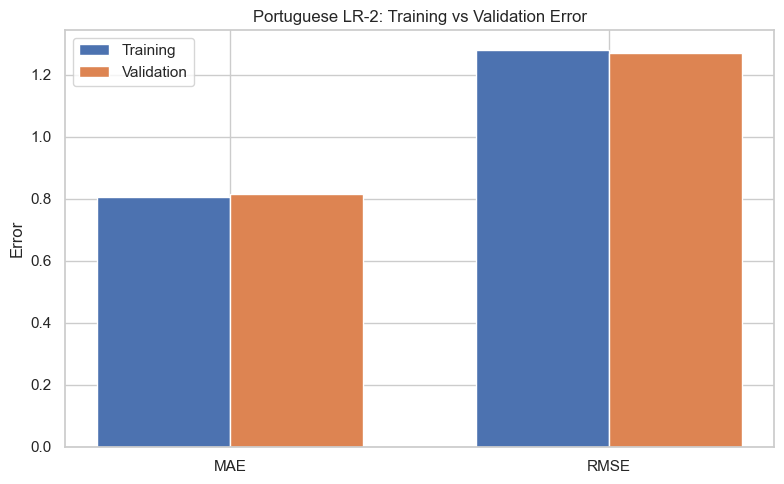

In [9]:
metrics = ["MAE", "RMSE"]
train_values = [train_mae, train_rmse]
val_values = [val_mae, val_rmse]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    train_values,
    width,
    label="Training"
)

plt.bar(
    x + width / 2,
    val_values,
    width,
    label="Validation"
)

plt.xticks(x, metrics)
plt.ylabel("Error")
plt.title("Portuguese LR-2: Training vs Validation Error")
plt.legend()

save_plot("LR2_Training_vs_Validation_Error.png")

Visualize RMSE across five folds

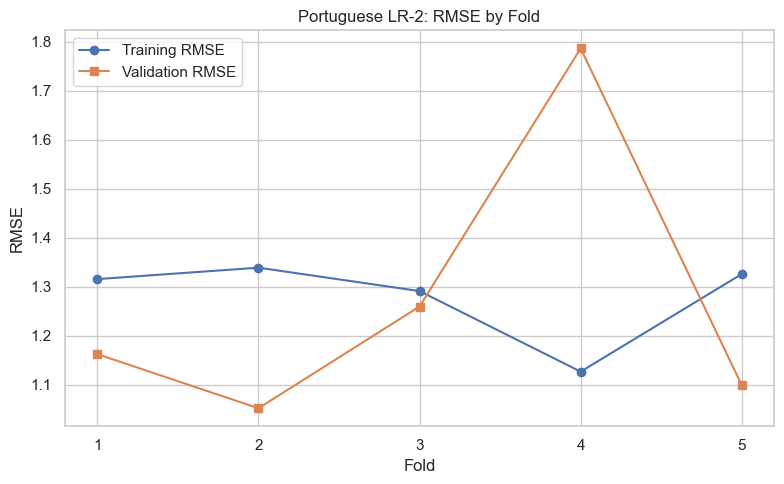

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    fold_results["Fold"],
    fold_results["Train RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    fold_results["Fold"],
    fold_results["Validation RMSE"],
    marker="s",
    label="Validation RMSE"
)

plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.title("Portuguese LR-2: RMSE by Fold")
plt.xticks(range(1, 6))
plt.legend()

save_plot("LR2_RMSE_By_Fold.png")

Generate out-of-fold predictions

In [11]:
oof_predictions = cross_val_predict(
    lr_model,
    X_train,
    y_train,
    cv=cv
)

actual = y_train.to_numpy()
residuals = actual - oof_predictions

oof_df = pd.DataFrame({
    "Actual G3": actual,
    "Predicted G3": oof_predictions,
    "Residual": residuals,
    "Absolute Error": np.abs(residuals)
})

display(oof_df.head())

oof_df.to_csv(
    output_dir / "LR2_OOF_Predictions.csv",
    index=False
)

,Actual G3,Predicted G3,Residual,Absolute Error
0,18,18.826235,-0.826235,0.826235
1,12,11.541638,0.458362,0.458362
2,12,11.179425,0.820575,0.820575
3,13,12.366210,0.633790,0.633790
4,10,11.214198,-1.214198,1.214198


Visualize actual vs predicted grades

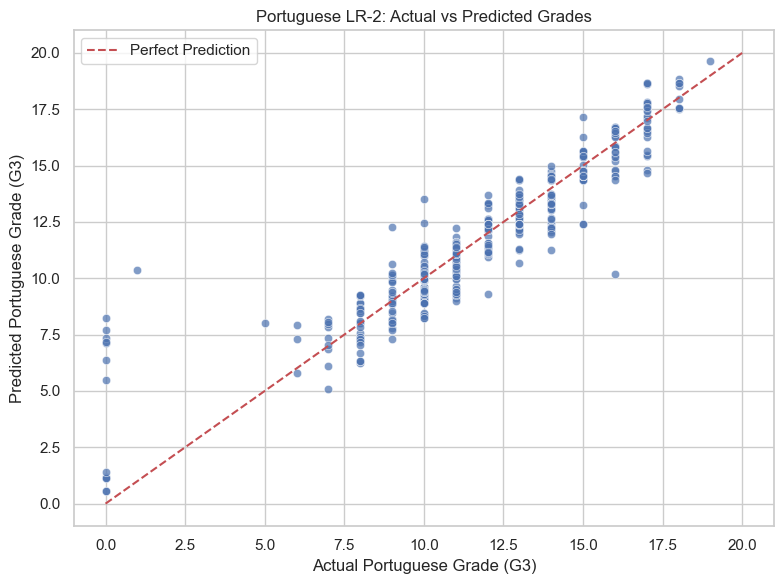

In [12]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=actual,
    y=oof_predictions,
    alpha=0.7
)

plt.plot(
    [0, 20],
    [0, 20],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Portuguese Grade (G3)")
plt.ylabel("Predicted Portuguese Grade (G3)")
plt.title("Portuguese LR-2: Actual vs Predicted Grades")

plt.xlim(-1, 21)
plt.ylim(-1, 21)
plt.legend()

save_plot("LR2_Actual_vs_Predicted.png")

Visualize residuals vs predicted values

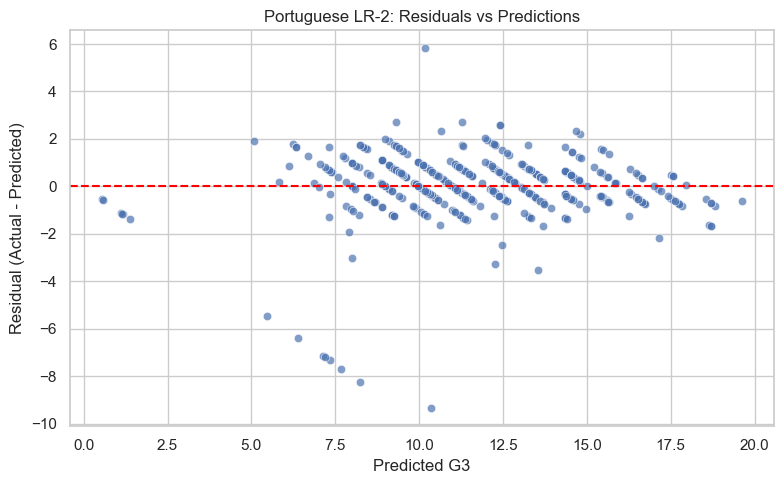

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=oof_predictions,
    y=residuals,
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted G3")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Portuguese LR-2: Residuals vs Predictions")

save_plot("LR2_Residuals_vs_Predicted.png")

Visualize residual distribution

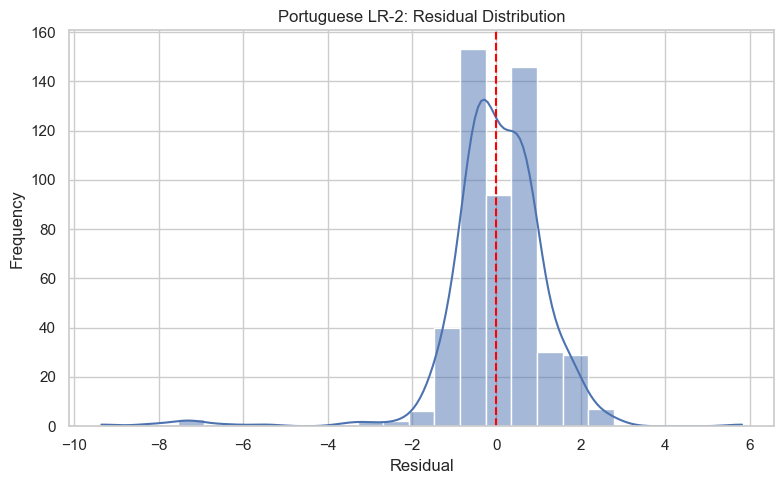

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=25,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Portuguese LR-2: Residual Distribution")

save_plot("LR2_Residual_Distribution.png")

Visualize absolute error distribution

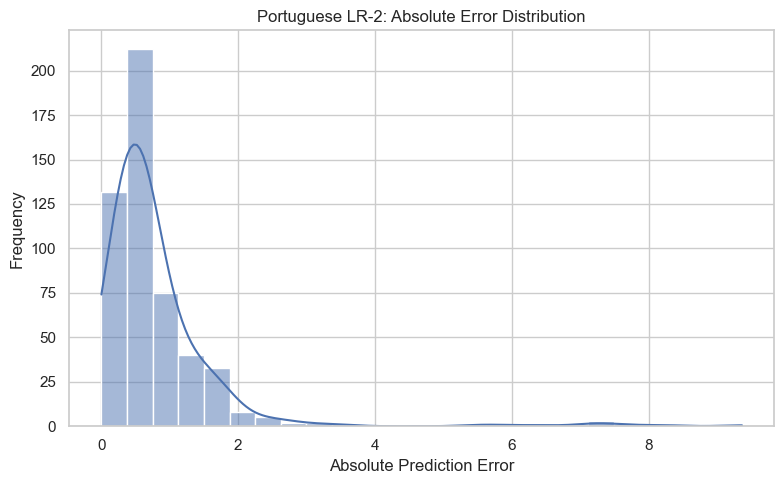

In [15]:
absolute_errors = np.abs(residuals)

plt.figure(figsize=(8, 5))

sns.histplot(
    absolute_errors,
    bins=25,
    kde=True
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Frequency")
plt.title("Portuguese LR-2: Absolute Error Distribution")

save_plot("LR2_Absolute_Error_Distribution.png")

Calculate grade prediction accuracy

In [16]:
rounded_predictions = np.clip(
    np.rint(oof_predictions),
    0,
    20
).astype(int)

exact_accuracy = (
    np.mean(rounded_predictions == actual) * 100
)

within_1 = (
    np.mean(np.abs(actual - oof_predictions) <= 1)
    * 100
)

within_2 = (
    np.mean(np.abs(actual - oof_predictions) <= 2)
    * 100
)

print("=" * 60)
print("PORTUGUESE LR-2 GRADE ACCURACY")
print("=" * 60)

print(f"Exact Accuracy  : {exact_accuracy:.2f}%")
print(f"Within ±1 Grade : {within_1:.2f}%")
print(f"Within ±2 Grades: {within_2:.2f}%")

PORTUGUESE LR-2 GRADE ACCURACY
Exact Accuracy  : 42.20%
Within ±1 Grade : 77.84%
Within ±2 Grades: 95.57%


Visualize grade accuracy

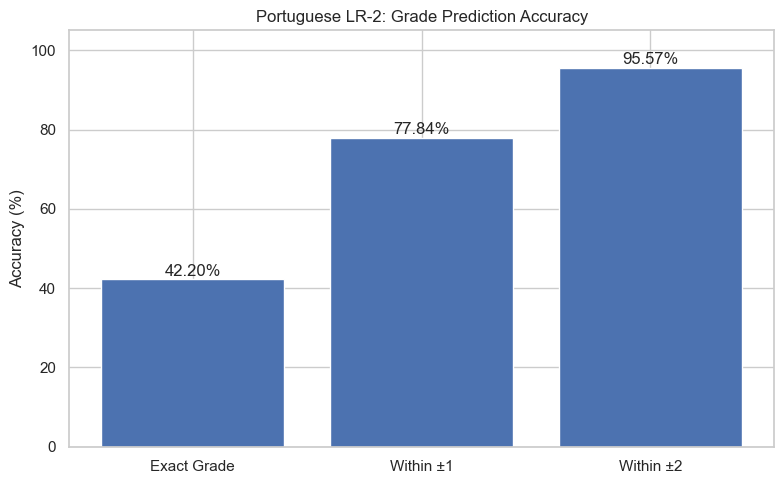

In [17]:
categories = [
    "Exact Grade",
    "Within ±1",
    "Within ±2"
]

values = [
    exact_accuracy,
    within_1,
    within_2
]

plt.figure(figsize=(8, 5))

bars = plt.bar(categories, values)

plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

plt.title("Portuguese LR-2: Grade Prediction Accuracy")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

save_plot("LR2_Grade_Accuracy.png")

Calculate pass/fail classification metrics

In [18]:
actual_binary = (actual >= 10).astype(int)
predicted_binary = (oof_predictions >= 10).astype(int)

pass_fail_accuracy = accuracy_score(
    actual_binary,
    predicted_binary
)

precision = precision_score(
    actual_binary,
    predicted_binary,
    zero_division=0
)

recall = recall_score(
    actual_binary,
    predicted_binary,
    zero_division=0
)

f1 = f1_score(
    actual_binary,
    predicted_binary,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    actual_binary,
    predicted_binary,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) else 0
)

print("=" * 60)
print("PORTUGUESE LR-2 PASS/FAIL METRICS")
print("=" * 60)

print(f"Accuracy   : {pass_fail_accuracy * 100:.2f}%")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score   : {f1:.4f}")

print("\nCONFUSION MATRIX")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

PORTUGUESE LR-2 PASS/FAIL METRICS
Accuracy   : 87.86%
Precision  : 0.9818
Recall     : 0.8710
Specificity: 0.9176
F1 Score   : 0.9231

CONFUSION MATRIX
TN: 78
FP: 7
FN: 56
TP: 378


Visualize the confusion matrix

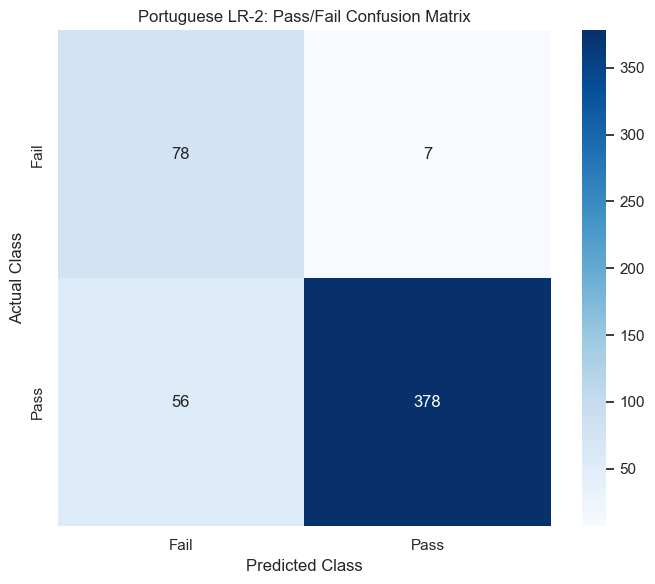

In [19]:
cm = confusion_matrix(
    actual_binary,
    predicted_binary,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Portuguese LR-2: Pass/Fail Confusion Matrix")

save_plot("LR2_Confusion_Matrix.png")

Visualize classification metrics

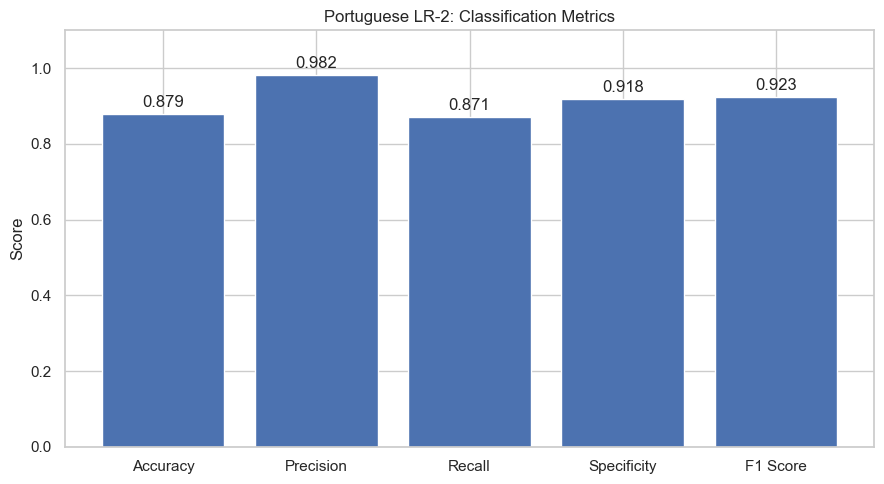

In [20]:
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1 Score"
]

metric_values = [
    pass_fail_accuracy,
    precision,
    recall,
    specificity,
    f1
]

plt.figure(figsize=(9, 5))

bars = plt.bar(metric_names, metric_values)

plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("Portuguese LR-2: Classification Metrics")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

save_plot("LR2_Classification_Metrics.png")

Generate and visualize the learning curve

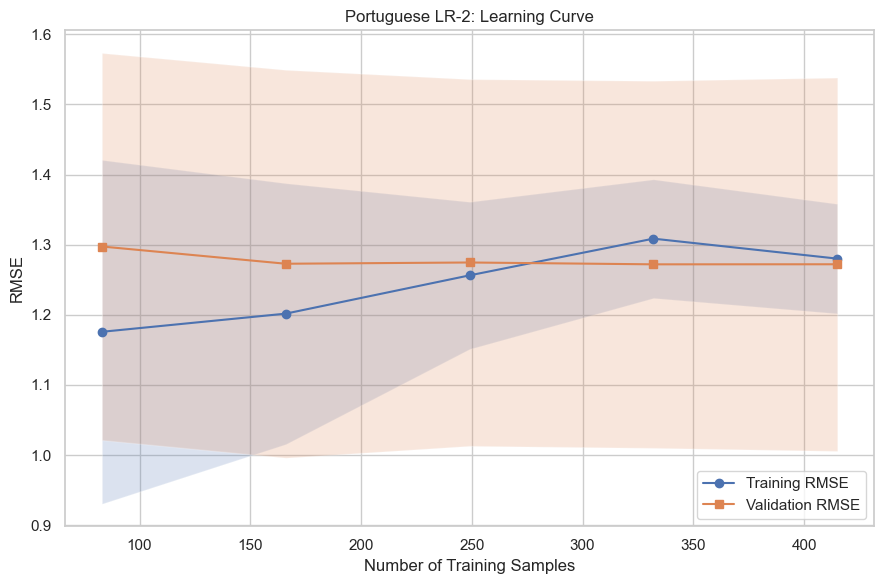

In [21]:
train_sizes, train_scores, val_scores = learning_curve(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

train_rmse_curve = np.sqrt(-train_scores)
val_rmse_curve = np.sqrt(-val_scores)

train_mean = train_rmse_curve.mean(axis=1)
train_std = train_rmse_curve.std(axis=1)

val_mean = val_rmse_curve.mean(axis=1)
val_std = val_rmse_curve.std(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training RMSE"
)

plt.plot(
    train_sizes,
    val_mean,
    marker="s",
    label="Validation RMSE"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

plt.xlabel("Number of Training Samples")
plt.ylabel("RMSE")
plt.title("Portuguese LR-2: Learning Curve")
plt.legend()

save_plot("LR2_Learning_Curve.png")

Visualize the generalization gap

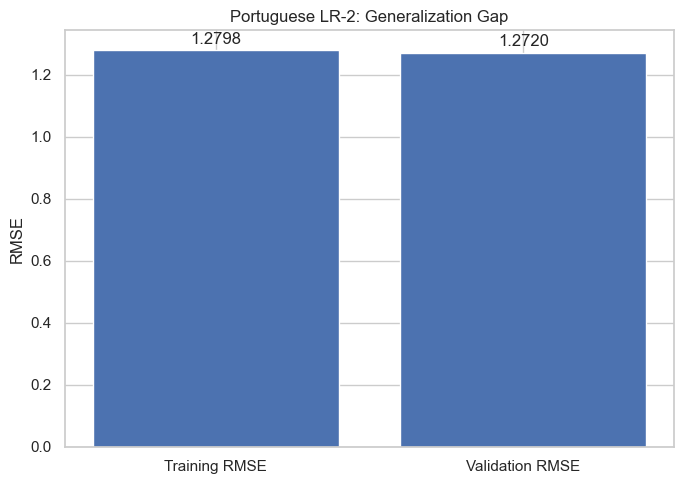

In [22]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Training RMSE", "Validation RMSE"],
    [train_rmse, val_rmse]
)

plt.ylabel("RMSE")
plt.title("Portuguese LR-2: Generalization Gap")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

save_plot("LR2_Generalization_Gap.png")

Train the final model on all Portuguese training records

In [23]:
final_lr_model = clone(lr_model)

final_lr_model.fit(X_train, y_train)

print("Final Portuguese Linear Regression trained.")
print("Training records:", len(X_train))
print("Features:", features)

Final Portuguese Linear Regression trained.
Training records: 519
Features: ['num__G1', 'num__G2']


Inspect the model coefficients and equation

In [24]:
coefficient_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": final_lr_model.coef_
})

intercept = final_lr_model.intercept_

display(coefficient_df)

print("Intercept:", round(intercept, 4))

print("\nPREDICTION EQUATION")
print(
    f"G3 = {intercept:.4f}"
    f" + ({final_lr_model.coef_[0]:.4f} × G1)"
    f" + ({final_lr_model.coef_[1]:.4f} × G2)"
)

coefficient_df.to_csv(
    output_dir / "LR2_Coefficients.csv",
    index=False
)

,Feature,Coefficient
0,num__G1,0.503005
1,num__G2,2.538953


Intercept: 11.7938

PREDICTION EQUATION
G3 = 11.7938 + (0.5030 × G1) + (2.5390 × G2)


Visualize model coefficients

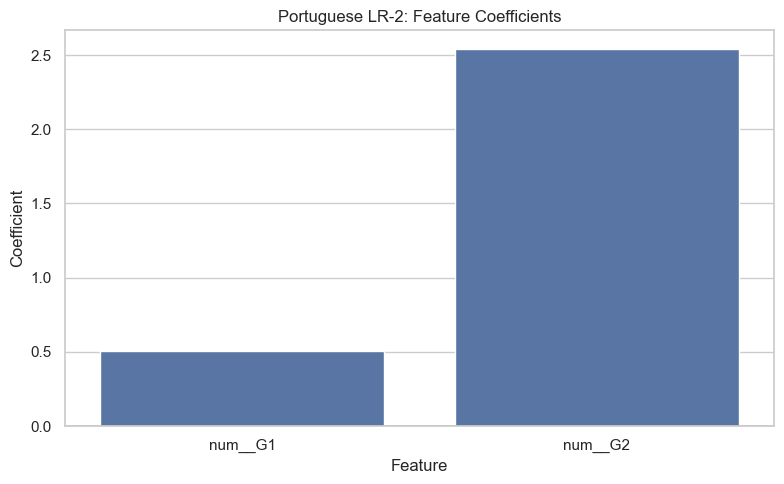

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=coefficient_df,
    x="Feature",
    y="Coefficient"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title("Portuguese LR-2: Feature Coefficients")
plt.xlabel("Feature")
plt.ylabel("Coefficient")

save_plot("LR2_Feature_Coefficients.png")

Save the final Portuguese model

In [26]:
model_bundle = {
    "model": final_lr_model,
    "model_name": "Linear Regression",
    "experiment": "LR-2",
    "dataset": "Portuguese",
    "features": features,
    "input_type": "preprocessed",
    "target": "G3",
    "pass_threshold": 10,
    "parameters": final_lr_model.get_params(),
    "cv_validation_rmse": float(val_rmse),
    "cv_validation_mae": float(val_mae),
    "cv_validation_r2": float(val_r2)
}

model_path = (
    models_dir / "final_portuguese_linear_regression_LR2.joblib"
)

joblib.dump(model_bundle, model_path)

print("Model saved successfully:")
print(model_path)

Model saved successfully:
C:\Users\U S E R\Desktop\ML Assigment\project\models\final_portuguese_linear_regression_LR2.joblib


Load and verify the saved model

In [27]:
loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["features"]

print("Model:", loaded_bundle["model_name"])
print("Experiment:", loaded_bundle["experiment"])
print("Dataset:", loaded_bundle["dataset"])
print("Features:", loaded_features)

sample_predictions = loaded_model.predict(
    X_train.head(5)
)

print("\nSample predictions:")
print(sample_predictions)

Model: Linear Regression
Experiment: LR-2
Dataset: Portuguese
Features: ['num__G1', 'num__G2']

Sample predictions:
[18.83497111 11.5306783  11.15435509 12.41286732 11.15435509]


Load and validate the held-out Portuguese test dataset

In [28]:
test_df = pd.read_csv(test_path)

required_columns = loaded_features + ["G3"]

missing_columns = [
    col for col in required_columns
    if col not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing test columns: {missing_columns}"
    )

X_test = test_df[loaded_features].copy()
y_test = test_df["G3"].copy()

assert X_test.notna().all().all()
assert y_test.notna().all()

print("Test records:", len(test_df))
print("Test features:", X_test.shape[1])

display(test_df.head())

Test records: 130
Test features: 2


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__activities_yes,cat__nursery_no,cat__nursery_yes,cat__higher_no,cat__higher_yes,cat__internet_no,cat__internet_yes,cat__romantic_no,cat__romantic_yes,G3
0,0.987932,1.350140,1.591423,-0.754310,0.121054,-0.382133,-0.971942,-1.12733,0.652599,-0.539674,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,19
1,-0.629534,0.456361,-1.180216,-0.754310,0.121054,-0.382133,-2.012020,-0.18668,-0.196270,0.490072,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,12
2,0.987932,1.350140,1.591423,0.555011,0.121054,-0.382133,0.068136,-0.18668,1.501468,-0.539674,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,18
3,-0.629534,1.350140,1.591423,-0.754310,0.121054,-0.382133,1.108214,-0.18668,-1.045139,-0.539674,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,11
4,-1.438267,-1.331196,-1.180216,-0.754310,0.121054,-0.382133,-0.971942,-0.18668,0.652599,0.490072,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,11


Evaluate the final model on the test dataset

In [29]:
test_predictions = loaded_model.predict(X_test)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_mse = mean_squared_error(
    y_test,
    test_predictions
)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print("=" * 65)
print("FINAL PORTUGUESE LR-2 TEST RESULTS")
print("=" * 65)

print(f"Test MAE  : {test_mae:.4f}")
print(f"Test MSE  : {test_mse:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")
print(f"Test R²   : {test_r2:.4f}")

print("\nCross-validation vs test:")
print(f"Validation RMSE : {val_rmse:.4f}")
print(f"Test RMSE       : {test_rmse:.4f}")

FINAL PORTUGUESE LR-2 TEST RESULTS
Test MAE  : 0.7328
Test MSE  : 1.3663
Test RMSE : 1.1689
Test R²   : 0.8599

Cross-validation vs test:
Validation RMSE : 1.2720
Test RMSE       : 1.1689


Calculate test grade prediction accuracy

In [30]:
test_actual = y_test.to_numpy()

test_rounded = np.clip(
    np.rint(test_predictions),
    0,
    20
).astype(int)

test_exact = (
    np.mean(test_rounded == test_actual) * 100
)

test_within_1 = (
    np.mean(
        np.abs(test_actual - test_predictions) <= 1
    ) * 100
)

test_within_2 = (
    np.mean(
        np.abs(test_actual - test_predictions) <= 2
    ) * 100
)

print("=" * 60)
print("PORTUGUESE LR-2 TEST GRADE ACCURACY")
print("=" * 60)

print(f"Exact Accuracy  : {test_exact:.2f}%")
print(f"Within ±1 Grade : {test_within_1:.2f}%")
print(f"Within ±2 Grades: {test_within_2:.2f}%")


PORTUGUESE LR-2 TEST GRADE ACCURACY
Exact Accuracy  : 40.77%
Within ±1 Grade : 84.62%
Within ±2 Grades: 97.69%


Calculate test pass/fail classification metrics

In [31]:
test_actual_binary = (
    test_actual >= 10
).astype(int)

test_predicted_binary = (
    test_predictions >= 10
).astype(int)

test_accuracy = accuracy_score(
    test_actual_binary,
    test_predicted_binary
)

test_precision = precision_score(
    test_actual_binary,
    test_predicted_binary,
    zero_division=0
)

test_recall = recall_score(
    test_actual_binary,
    test_predicted_binary,
    zero_division=0
)

test_f1 = f1_score(
    test_actual_binary,
    test_predicted_binary,
    zero_division=0
)

test_tn, test_fp, test_fn, test_tp = confusion_matrix(
    test_actual_binary,
    test_predicted_binary,
    labels=[0, 1]
).ravel()

test_specificity = (
    test_tn / (test_tn + test_fp)
    if (test_tn + test_fp) else 0
)

print("=" * 60)
print("PORTUGUESE LR-2 TEST CLASSIFICATION")
print("=" * 60)

print(f"Accuracy   : {test_accuracy * 100:.2f}%")
print(f"Precision  : {test_precision:.4f}")
print(f"Recall     : {test_recall:.4f}")
print(f"Specificity: {test_specificity:.4f}")
print(f"F1 Score   : {test_f1:.4f}")

print("\nCONFUSION MATRIX")
print("TN:", test_tn)
print("FP:", test_fp)
print("FN:", test_fn)
print("TP:", test_tp)

PORTUGUESE LR-2 TEST CLASSIFICATION
Accuracy   : 90.77%
Precision  : 1.0000
Recall     : 0.8957
Specificity: 1.0000
F1 Score   : 0.9450

CONFUSION MATRIX
TN: 15
FP: 0
FN: 12
TP: 103


Visualize actual vs predicted test grades

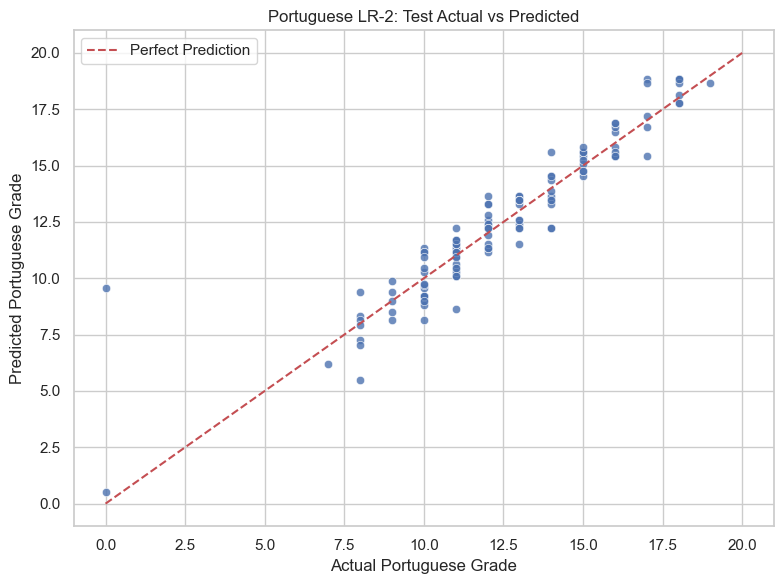

In [32]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=test_actual,
    y=test_predictions,
    alpha=0.8
)

plt.plot(
    [0, 20],
    [0, 20],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Portuguese Grade")
plt.ylabel("Predicted Portuguese Grade")
plt.title("Portuguese LR-2: Test Actual vs Predicted")

plt.xlim(-1, 21)
plt.ylim(-1, 21)
plt.legend()

save_plot("LR2_Test_Actual_vs_Predicted.png")

Visualize test residuals

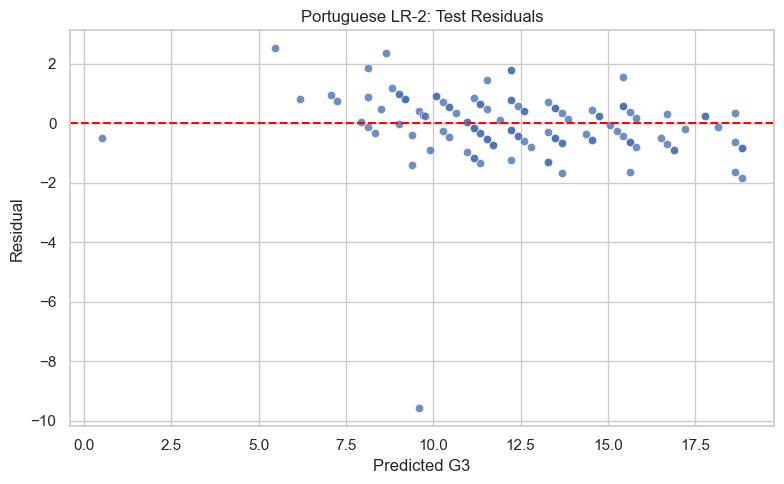

In [33]:
test_residuals = test_actual - test_predictions

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=test_predictions,
    y=test_residuals,
    alpha=0.8
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted G3")
plt.ylabel("Residual")
plt.title("Portuguese LR-2: Test Residuals")

save_plot("LR2_Test_Residuals.png")

Visualize the test confusion matrix

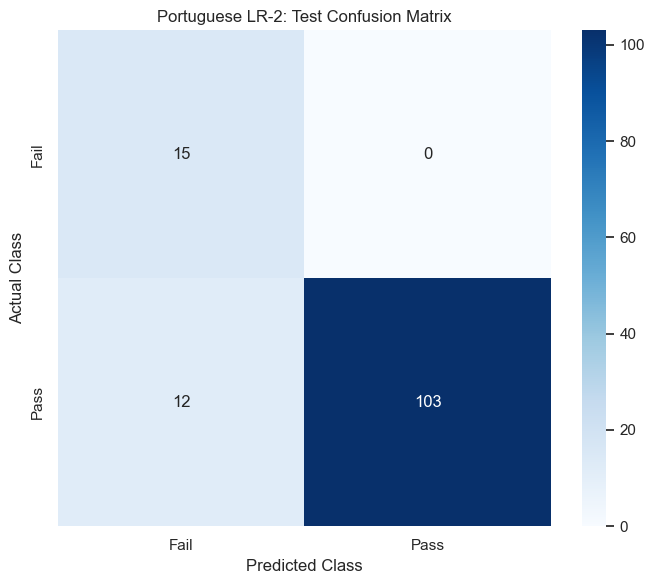

In [34]:
test_cm = confusion_matrix(
    test_actual_binary,
    test_predicted_binary,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Portuguese LR-2: Test Confusion Matrix")

save_plot("LR2_Test_Confusion_Matrix.png")

Save all final evaluation results

In [35]:
cv_summary = pd.DataFrame([{
    "Model": "Portuguese Linear Regression LR-2",
    "Train MAE": train_mae,
    "Validation MAE": val_mae,
    "Train MSE": train_mse,
    "Validation MSE": val_mse,
    "Train RMSE": train_rmse,
    "Validation RMSE": val_rmse,
    "Train R2": train_r2,
    "Validation R2": val_r2,
    "RMSE Gap": rmse_gap,
    "Exact Accuracy (%)": exact_accuracy,
    "Within 1 Grade (%)": within_1,
    "Within 2 Grades (%)": within_2,
    "Pass/Fail Accuracy (%)": pass_fail_accuracy * 100,
    "Precision": precision,
    "Recall": recall,
    "Specificity": specificity,
    "F1 Score": f1,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}])

test_summary = pd.DataFrame([{
    "Model": "Portuguese Linear Regression LR-2",
    "Test MAE": test_mae,
    "Test MSE": test_mse,
    "Test RMSE": test_rmse,
    "Test R2": test_r2,
    "Exact Accuracy (%)": test_exact,
    "Within 1 Grade (%)": test_within_1,
    "Within 2 Grades (%)": test_within_2,
    "Pass/Fail Accuracy (%)": test_accuracy * 100,
    "Precision": test_precision,
    "Recall": test_recall,
    "Specificity": test_specificity,
    "F1 Score": test_f1,
    "TN": test_tn,
    "FP": test_fp,
    "FN": test_fn,
    "TP": test_tp
}])

test_prediction_df = pd.DataFrame({
    "Actual G3": test_actual,
    "Predicted G3": test_predictions,
    "Rounded Predicted G3": test_rounded,
    "Absolute Error": np.abs(test_residuals),
    "Actual Pass/Fail": test_actual_binary,
    "Predicted Pass/Fail": test_predicted_binary
})

cv_summary.to_csv(
    output_dir / "LR2_Final_CV_Results.csv",
    index=False
)

test_summary.to_csv(
    output_dir / "LR2_Final_Test_Results.csv",
    index=False
)

test_prediction_df.to_csv(
    output_dir / "LR2_Final_Test_Predictions.csv",
    index=False
)

display(cv_summary.round(4))
display(test_summary.round(4))

print("All Portuguese final model results saved.")

,Model,Train MAE,Validation MAE,Train MSE,Validation MSE,Train RMSE,Validation RMSE,Train R2,Validation R2,RMSE Gap,...,Within 2 Grades (%),Pass/Fail Accuracy (%),Precision,Recall,Specificity,F1 Score,TN,FP,FN,TP
0,Portuguese Linear Regression LR-2,0.8058,0.8163,1.644,1.6889,1.2798,1.272,0.8441,0.8417,-0.0078,...,95.5684,87.8613,0.9818,0.871,0.9176,0.9231,78,7,56,378


,Model,Test MAE,Test MSE,Test RMSE,Test R2,Exact Accuracy (%),Within 1 Grade (%),Within 2 Grades (%),Pass/Fail Accuracy (%),Precision,Recall,Specificity,F1 Score,TN,FP,FN,TP
0,Portuguese Linear Regression LR-2,0.7328,1.3663,1.1689,0.8599,40.7692,84.6154,97.6923,90.7692,1.0,0.8957,1.0,0.945,15,0,12,103


All Portuguese final model results saved.
